In [ ]:
import yaml
yaml_paths = './data/data_dir.yaml'
with open(yaml_paths, 'r') as yaml_file:
    file_paths = yaml.safe_load(yaml_file)
import pickle
save_dir = file_paths['WSI1_data']['WSI1_inference_dir']
with open(save_dir, 'rb') as f:
    patient_data = pickle.load(f)

In [3]:
#This code to load all real patch 
import numpy as np
import matplotlib.pyplot as plt
import numpy as np

Patient = 'Patient_A'
Patient_name = patient_data[Patient]['Patient_name']

import h5py

def load_patients_info_img(patient_name):
    bunch_dict = patient_data[Patient]['bunch_dict']
    slide_name_list = patient_data[Patient]['slide_name_list']
    bunch_name_list = patient_data[Patient]['bunch_name_list']

    all_patch_data = []
    save_dir = file_paths['WSI1_data']['Patches_dir']
    all_patch_data_info = []
    for i in range(len(slide_name_list)):
        slide_name = slide_name_list[i]
        with h5py.File(save_dir + patient_name + '-' + slide_name + '.hdf5', 'r') as f:
            patch_data = f['patches']['0'][:]
            classes = f['classes'][:]
        if np.unique(classes).shape[0] == 1:
            print('Only one class in this slide')
            all_patch_data.append(patch_data)
            # all_patch_data_info.append([slide_name.replace('-Flip', '')+bunch_name_list[i]]*250)
            slide = slide_name.replace('-Flip', '')
            if slide == 'N1_Th1-A5':
                slide = 'Th1-A5'
            punch_name = slide.split('-')[0]+bunch_name_list[i]+'-'+slide.split('-')[1]
            all_patch_data_info.append([punch_name]*len(patch_data))
            # all_patch_data_info.append((slide_name, 'Only one class in this slide'))
        else:
            punch_nameid = bunch_name_list[i]
            idx_patches = np.where(classes == bunch_dict[punch_nameid])[0]
            if len(idx_patches) == 0:
                print(bunch_name_list[i] , slide_name)
                if slide_name == 'N1_Th1-A5-Flip':
                    bunch_name = b'N1'
                if slide_name == 'M2-A13-Flip' and (bunch_name_list[i] == 'a'):
                    bunch_name = b'9'            
                if slide_name == 'M2-A13-Flip' and (bunch_name_list[i] == 'b'):
                    bunch_name = b'10'            
                if slide_name == 'M1-B5-Flip' and (bunch_name_list[i] == 'a'):
                    bunch_name = b'M1'
                print(bunch_name , slide_name)
                idx_patches = np.where(classes == bunch_name)[0]
                all_patch_data.append(patch_data[idx_patches])
                slide = slide_name.replace('-Flip', '')
                if slide == 'N1_Th1-A5':
                    slide = 'Th1-A5'
                punch_name = slide.split('-')[0]+bunch_name_list[i]+'-'+slide.split('-')[1]
                all_patch_data_info.append([punch_name]*len(idx_patches))
                # all_patch_data_info.append((slide_name, 'No patch with the expected bunch name, use all patches with the same patient name'))
            else:
                all_patch_data.append(patch_data[idx_patches])
                slide = slide_name.replace('-Flip', '')
                if slide == 'N1_Th1-A5':
                    slide = 'Th1-A5'
                punch_name = slide.split('-')[0]+bunch_name_list[i]+'-'+slide.split('-')[1]
                all_patch_data_info.append([punch_name]*len(idx_patches))
        print(all_patch_data[-1].shape)
    all_patch_data = np.concatenate(all_patch_data, axis = 0)
    all_patch_data_info = np.concatenate(all_patch_data_info)
    return all_patch_data, all_patch_data_info
all_patch_data, all_patch_data_info = load_patients_info_img(Patient_name)

Only one class in this slide
(250, 224, 224, 3)
(250, 224, 224, 3)
(250, 224, 224, 3)
(250, 224, 224, 3)
(250, 224, 224, 3)
(250, 224, 224, 3)
Only one class in this slide
(250, 224, 224, 3)
Only one class in this slide
(250, 224, 224, 3)


In [4]:
import os
os.chdir(file_paths['WSI1_data']['DIFFAE_model_dir'])
from templates import *
from templates_cls import *
from experiment_classifier import ClsModel
import pickle
from PIL import Image
import torchvision.transforms as transforms
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis  
import pickle
import torchvision
import cv2
import torchvision.transforms.functional as fn
import numpy as np
from PIL import Image
import torch
device = 'cuda:0'
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
conf = grade224_autoenc_130M()
# load DIFFAE models
model = LitModel(conf)
state = torch.load(
    'checkpoints/grade224_autoenc_130M/last.ckpt',
    map_location='cpu',
    weights_only=False
)
model.load_state_dict(state['state_dict'], strict=False)
model.ema_model.eval()
model.ema_model.to(device)
transform =   transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])
from tqdm import tqdm
def extract_feature(all_patch_data, all_patch_data_info):
    DIFFAE_extracted_feature = []
    class_name = []
    org_name = []
    for patch in tqdm(all_patch_data):
        patch = Image.fromarray(patch)
        patch = transform(patch).unsqueeze(0).to(device)
        with torch.no_grad():
            feature = model.encode(patch)
        DIFFAE_extracted_feature.append(feature.cpu().numpy().squeeze())
    DIFFAE_extracted_feature = np.array(DIFFAE_extracted_feature)
    class_name = np.array(all_patch_data_info)
    return DIFFAE_extracted_feature, class_name
DIFFAE_extracted_feature, class_name = extract_feature(all_patch_data, all_patch_data_info)
    
        

Global seed set to 0


Model params: 118.64 M


100%|██████████| 2000/2000 [00:23<00:00, 85.72it/s] 


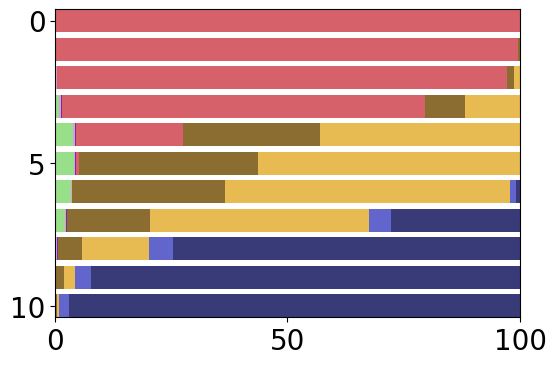

In [ ]:
#compute distances between classes in the DIFFAE feature space then plot the distance matrix as a heatmap

import numpy as np
from scipy.spatial.distance import cdist
#defind metric to find nearest neighbor in the latent space of real and synthetic images. 
def find_nearest_neighbor(feature, feature_set, metric='euclidean'):
    if metric == 'euclidean':
        dist = cdist(feature.reshape(1, -1), feature_set, metric=metric)
    
    #cosine similarity
    elif metric == 'cosine':
        dist = cdist(feature.reshape(1, -1), feature_set, metric=metric)
    # fractional metrics
    elif metric == 'fractional':   
        dist = cdist(feature.reshape(1, -1), feature_set, metric=metric)
    # SNN metric
    elif metric == 'SNN':
        dist = cdist(feature.reshape(1, -1), feature_set, metric='euclidean')
        dist = np.exp(-dist)
        dist = dist / np.sum(dist)
   
    return dist
from sklearn.metrics import pairwise_distances
# distance_df.to_csv('DIFFAE_feature_distance_matrix.csv')
# plt.figure(figsize=(10,8))
import seaborn as sns
#take the average distance between classes and plot as a heatmap
def compute_centroid_distance(Patient_name, DIFFAE_extracted_feature, class_name):
    class_order = patient_data[Patient]['class_order']
    centroidsMat = []
    for class_idx in class_order:
        idx = np.where(class_name == class_idx)[0]
        centroid = np.mean(DIFFAE_extracted_feature[idx], axis=0)
        centroidsMat.append(centroid)
    centroidsMat = np.array(centroidsMat)
    return centroidsMat, class_order
centroidsMat, class_order = compute_centroid_distance(Patient_name, DIFFAE_extracted_feature, class_name)
from sklearn.metrics.pairwise import cosine_distances
import scipy

sparseMatCentroids = scipy.sparse.csr_matrix(centroidsMat)
distanceMatCentroids = cosine_distances(sparseMatCentroids)
average_distance_df = pd.DataFrame(distanceMatCentroids, index=class_order, columns=class_order)
plt.figure(figsize=(6,5))
sns.heatmap(average_distance_df, cmap='gray')
plt.xticks([])
plt.yticks([])
#increase the font size of colorbar ticks
cbar = plt.gcf().axes[-1].tick_params(labelsize=25)
# plt.legend(fontsize=20)

# plt.title('Average Distance between Classes in DIFFAE Feature Space', fontsize=20)
plt.tight_layout()


##neighborhood analysis for  interpolated vectors in DIFFAE latent spaces with different traversal techniques
traversal_dir = 'sample_across'
# traversal_dir = 'Centroid'
org_class_list = []
target_class_list = []
class_traverse = patient_data[Patient]['Traverse_path']
color_dict = patient_data[Patient]['color_dict']
for i in range(len(class_traverse)): 
    for j in range(i+1, len(class_traverse)):
        org_class_list.append(class_traverse[i])
        target_class_list.append(class_traverse[j])
for org_class, target_class in zip(org_class_list, target_class_list):
    org_idx = np.where(all_patch_data_info == org_class)[0]
    target_idx = np.where(all_patch_data_info == target_class)[0]
    print(f'{org_class} to {target_class}: {len(org_idx)}')
    DIFFAE_syn_extracted_feature = []
    class_syn_name = []
    num_traverse_step = 10
    for i in range(min(len(org_idx), len(target_idx))):
    # for i in range(len(org_idx)):
        if traversal_dir == 'sample_across':
            target_point = DIFFAE_extracted_feature[target_idx[i]]
        if traversal_dir == 'centroid':
            target_point = 1.2*(centroidsMat[class_order.index(target_class)] - centroidsMat[class_order.index(org_class)])+ DIFFAE_extracted_feature[org_idx[i]]
        for alpha in np.linspace(0, 1, num_traverse_step+1):
            DIFFAE_syn_extracted_feature.append((1-alpha)*DIFFAE_extracted_feature[org_idx[i]] + alpha*target_point)
            class_syn_name.append(f'step_{int(alpha*num_traverse_step)}')
    DIFFAE_syn_extracted_feature = np.array(DIFFAE_syn_extracted_feature)
    print(DIFFAE_syn_extracted_feature.shape)
    
    #use L1 metric to find 10 nearest neighbor
    nearest_neighbor_idx_list = {}
    for traverse_step in np.unique(class_syn_name):
        nearest_neighbor_idx_list[traverse_step] = []
    metric = 'cosine'

    latent_space = DIFFAE_extracted_feature
    for i in range(DIFFAE_syn_extracted_feature.shape[0]):
        dist = find_nearest_neighbor(DIFFAE_syn_extracted_feature[i], latent_space, metric=metric)
        nearest_neighbor_idx = np.argsort(dist)[0][:10]
        nearest_neighbor_idx_list[class_syn_name[i]].append(nearest_neighbor_idx)
        
    for traverse_step in np.unique(class_syn_name):
        nearest_neighbor_idx_list[traverse_step] = np.array(nearest_neighbor_idx_list[traverse_step])

    classes = np.unique(all_patch_data_info)
    groups = ['step_0', 'step_1', 'step_2', 'step_3', 'step_4', 'step_5', 'step_6', 'step_7', 'step_8', 'step_9', 'step_10']
    data = np.array([[np.sum(all_patch_data_info[nearest_neighbor_idx_list[step_name]] == cls) for cls in class_order] for step_name in groups])

    # Convert to percentages (each row sums to 100%)
    row_sums = data.sum(axis=1, keepdims=True)
    percent_data = data / row_sums * 100

fig, ax = plt.subplots(figsize=(6,4))

left = np.zeros(len(groups))

for i, cls in enumerate(class_order):
    ax.barh(
        groups,
        percent_data[:, i],
        left=left,
        label=cls,
        color=color_dict[cls]
    )
    left += percent_data[:, i]

# ax.set_xticks([])
ax.set_xlim(0, 100)

# Show y ticks as 10, 8, 6, 4, 2, 0
yticks = [10, 5, 0]
ax.set_yticks(yticks)
ax.set_yticklabels(yticks, fontsize=20)
xticks = [0, 50, 100]
ax.set_xticks(xticks)
ax.set_xticklabels(xticks, fontsize=20)


# Keep reversed y-axis
ax.set_ylim(10.4, -0.4)
plt.savefig('./image/WSI1_inference_plot.png', dpi=300, bbox_inches='tight')
plt.show()

dict_keys(['KC01138', 'KC01888', 'KC02820'])
(250, 11, 224, 224, 3)


100%|██████████| 250/250 [00:02<00:00, 124.21it/s]


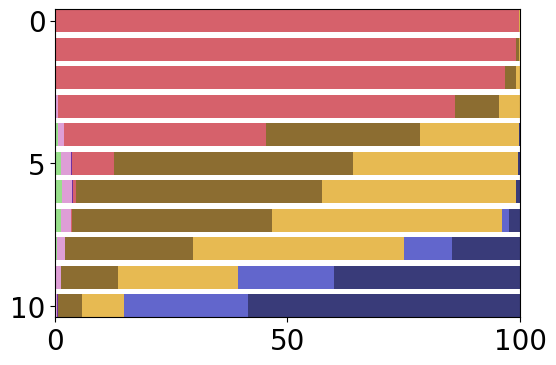

In [ ]:
#neighborhood analysis for  re-encoded vectors in different spaces with different traversal techniques
save_dir = file_paths['WSI1_data']['Reconstructed_latent_dir']
import pickle
with open(save_dir, 'rb') as f:
    save_file = pickle.load(f)
print(save_file.keys())
traversal_dir = 'sample_across'
# traversal_dir = 'centroids'
##choose latent space
latentspace = 'Re-encoded' # 'DIFFAE' or 'Re-encoded'
if latentspace == 'DIFFAE':
    latent_space = DIFFAE_extracted_feature
else:
    latent_space = save_file[Patient_name]['rec_feature']

save_dir = patient_data[Patient]['traversal_images_dir'][traversal_dir]
syn_data = pickle.load(open(save_dir, 'rb'))
if traversal_dir == 'sample_across':
    xT_type = 'org'
    if xT_type == 'org':
        syn_img_list = syn_data['traverse_image']['traverse_img_with_encoded_xT'].transpose(0,1,3,4,2)
    else:
        syn_img_list = syn_data['traverse_image_targetxT']['traverse_img_with_encoded_xT'].transpose(0,1,3,4,2)
else:
    syn_img_list = syn_data['img'][:,1:,:,:,:]
print(syn_img_list.shape)
DIFFAE_syn_extracted_feature = []
class_syn_name = []
# for j in range(syn_data['img'].shape[1]):
#     img = syn_data['img'][:,j,:,:,:]
from tqdm import tqdm
from PIL import Image
for j in range(syn_img_list.shape[1]):
    img = syn_img_list[:,j,:,:,:]
    img = img.astype(np.uint8)
    for patch in tqdm(img):
        patch = Image.fromarray(patch)
        patch = transform(patch).unsqueeze(0).to(device)
        with torch.no_grad():
            feature = model.encode(patch)
        DIFFAE_syn_extracted_feature.append(feature.cpu().numpy().squeeze())
        class_syn_name.append(f'step_{j}')
DIFFAE_syn_extracted_feature = np.array(DIFFAE_syn_extracted_feature)
class_syn_name = np.array(class_syn_name)

#From latent space of real and synthetic images. Determine the nearest neighbor in the latent space of real images for each synthetic image at each traverse step. 
color_dict = patient_data[Patient]['color_dict']
class_order = patient_data[Patient]['class_order']
import numpy as np
from scipy.spatial.distance import cdist
#defind metric to find nearest neighbor in the latent space of real and synthetic images. 
def find_nearest_neighbor(feature, feature_set, metric='euclidean'):
    if metric == 'euclidean':
        dist = cdist(feature.reshape(1, -1), feature_set, metric=metric)
    
    #cosine similarity
    elif metric == 'cosine':
        dist = cdist(feature.reshape(1, -1), feature_set, metric=metric)
    # fractional metrics
    elif metric == 'fractional':   
        dist = cdist(feature.reshape(1, -1), feature_set, metric=metric)
    # SNN metric
    elif metric == 'SNN':
        dist = cdist(feature.reshape(1, -1), feature_set, metric='euclidean')
        dist = np.exp(-dist)
        dist = dist / np.sum(dist)
   
    return dist

#use L1 metric to find 10 nearest neighbor
nearest_neighbor_idx_list = {}
nearest_neighbor_dist_list = {}
for traverse_step in np.unique(class_syn_name):
    nearest_neighbor_idx_list[traverse_step] = []
    nearest_neighbor_dist_list[traverse_step] = []
metric = 'cosine'

for i in range(DIFFAE_syn_extracted_feature.shape[0]):
    dist = find_nearest_neighbor(DIFFAE_syn_extracted_feature[i], latent_space, metric=metric)
    nearest_neighbor_idx = np.argsort(dist)[0][:10]
    nearest_neighbor_idx_list[class_syn_name[i]].append(nearest_neighbor_idx)
    nearest_neighbor_dist_list[class_syn_name[i]].append(dist[0][nearest_neighbor_idx])

for traverse_step in np.unique(class_syn_name):
    nearest_neighbor_idx_list[traverse_step] = np.array(nearest_neighbor_idx_list[traverse_step])
    nearest_neighbor_dist_list[traverse_step] = np.array(nearest_neighbor_dist_list[traverse_step])
import numpy as np
import matplotlib.pyplot as plt

classes = nearest_neighbor_idx_list.keys()
if len(classes) > 11:
    groups = ['step_1','step_2', 'step_3', 'step_4', 'step_5', 'step_6', 'step_7', 'step_8', 'step_9', 'step_10', 'step_11']
else:
    groups = ['step_0', 'step_1', 'step_2', 'step_3', 'step_4', 'step_5', 'step_6', 'step_7', 'step_8', 'step_9', 'step_10']
data = np.array([[np.sum(all_patch_data_info[nearest_neighbor_idx_list[step_name]] == cls) for cls in class_order] for step_name in groups])
# data = np.array([[np.sum(all_patch_data_info[nearest_neighbor_idx_list[step_name]] == cls) for cls in class_order] for step_name in groups])

# Convert to percentages (each row sums to 100%)
row_sums = data.sum(axis=1, keepdims=True)
percent_data = data / row_sums * 100
# fig, ax = plt.subplots(figsize=(5,5))

# bottom = np.zeros(len(groups))

# for i, cls in enumerate(class_order):
#     ax.bar(np.arange(11), percent_data[:, i], bottom=bottom, label=cls, color = color_dict[cls])
#     bottom += percent_data[:, i]
# plt.xticks([])
# # plt.xticks(fontsize=16)
# plt.yticks(fontsize=16)
# plt.ylim(0,100)
# plt.show()

fig, ax = plt.subplots(figsize=(6,4))

left = np.zeros(len(groups))

for i, cls in enumerate(class_order):
    ax.barh(
        groups,
        percent_data[:, i],
        left=left,
        label=cls,
        color=color_dict[cls]
    )
    left += percent_data[:, i]

# ax.set_xticks([])
ax.set_xlim(0, 100)

# Show y ticks as 10, 8, 6, 4, 2, 0
yticks = [10, 5, 0]
ax.set_yticks(yticks)
ax.set_yticklabels(yticks, fontsize=20)
xticks = [0, 50, 100]
ax.set_xticks(xticks)
ax.set_xticklabels(xticks, fontsize=20)

# Keep reversed y-axis
ax.set_ylim(10.4, -0.4)
plt.savefig('./image/WSI1_inference_plot_reencoded.png', dpi=300, bbox_inches='tight')

plt.show()


1


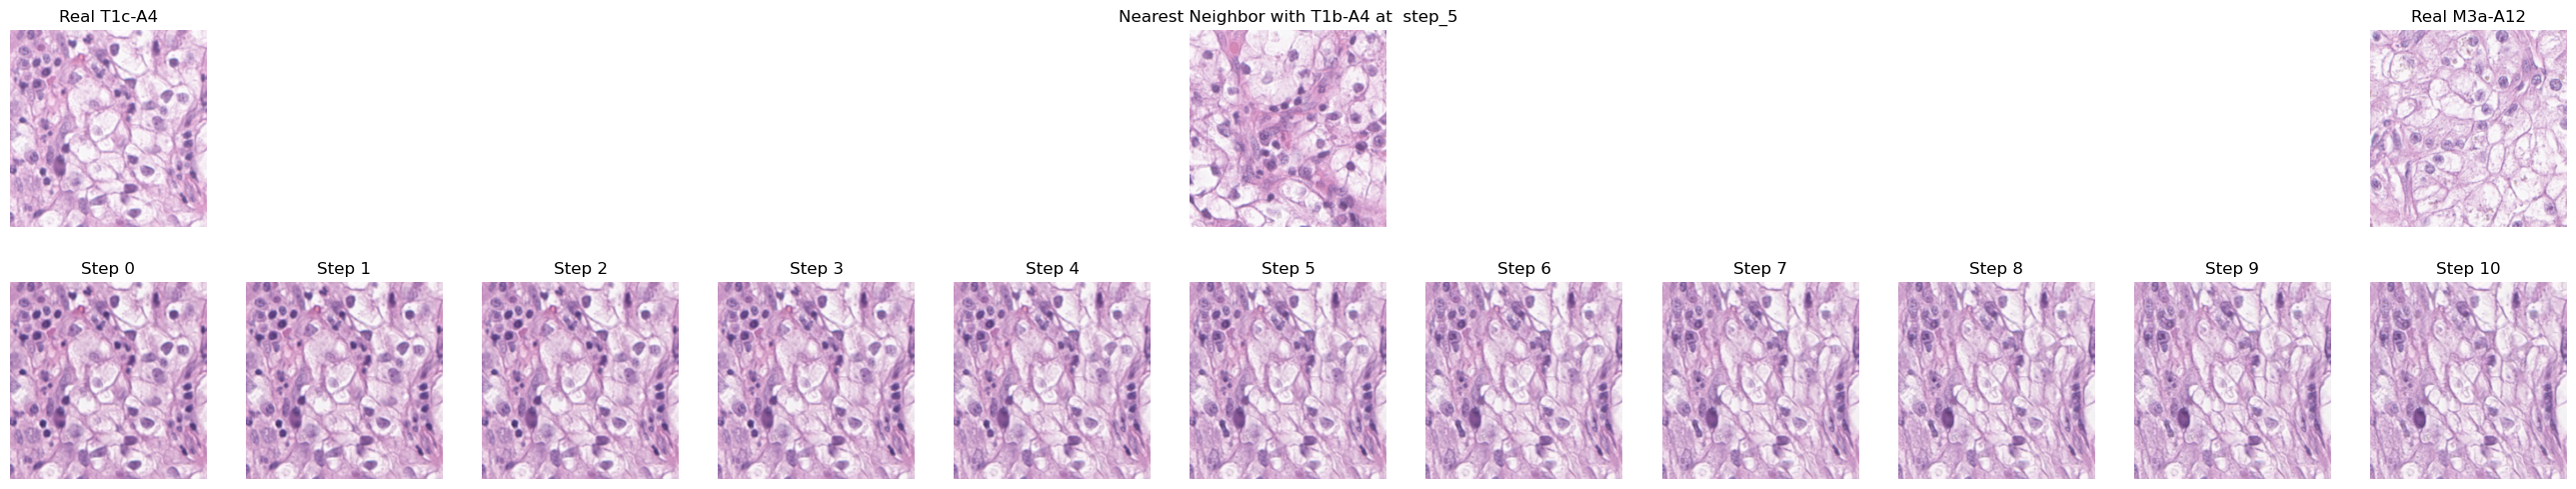

In [22]:
org_class = patient_data[Patient]['Traverse_path'][0]
target_class = patient_data[Patient]['Traverse_path'][1]
postive_class = patient_data[Patient]['postive_class']
negative_class = patient_data[Patient]['negative_class']
save_dir = patient_data[Patient]['traversal_images_dir']['sample_across']
syn_data = pickle.load(open(save_dir, 'rb'))
xT_type = 'org'
#at step_5, find all samples that have postive_class as nearest neighbor 
syn_step = 'step_5'
idx = np.where(np.isin(all_patch_data_info[nearest_neighbor_idx_list[syn_step][:, 0]], postive_class))[0]
dist = nearest_neighbor_dist_list[syn_step][idx, 0]
sorted_idx = np.argsort(dist)

#find the sample with the smallest distance. Change here to see other samples
chosen_idx =1 # 24,28, 35, 38, 42, 60, 69, 78, 87, 87, 99
print(chosen_idx)
nearest_idx = idx[sorted_idx[chosen_idx]] 
# nearest_idx = 152
if xT_type == 'org':
    syn_img_list = syn_data['traverse_image']
else:
    syn_img_list = syn_data['traverse_image_targetxT']

#plot the synthetic image at step_5 and the nearest neighbor image
plt.figure(figsize=(3*11, 3*2))
plt.subplot(2,11, 1)
org_real_image_idx = np.where(all_patch_data_info == org_class)[0][nearest_idx]
plt.imshow(all_patch_data[org_real_image_idx])
plt.axis('off')
plt.title(f'Real {org_class}')
plt.subplot(2, 11, 11)
target_real_image_idx = np.where(all_patch_data_info == target_class)[0][syn_img_list['random_seed'][nearest_idx]]
plt.imshow(all_patch_data[target_real_image_idx])
plt.axis('off')
plt.title(f'Real {target_class}')

plt.subplot(2, 11, 6)
plt.imshow(all_patch_data[nearest_neighbor_idx_list[syn_step][nearest_idx, 0]])
plt.title(f'Nearest Neighbor with {all_patch_data_info[nearest_neighbor_idx_list[syn_step][nearest_idx, 0]]} at  {syn_step}')
plt.axis('off')

for i in range(11):
    plt.subplot(2, 11, i+11+1)
    plt.imshow(syn_img_list['traverse_img_with_encoded_xT'][nearest_idx, i].transpose(1, 2, 0))
    plt.title(f'Step {i}')
    plt.axis('off')

this is real original image


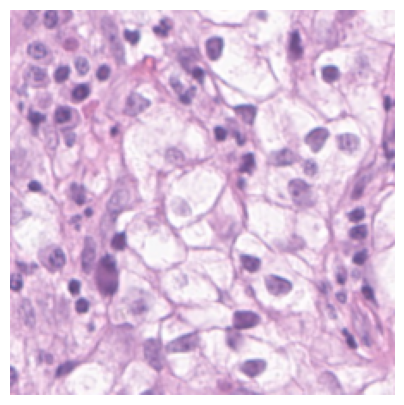

this is real target image


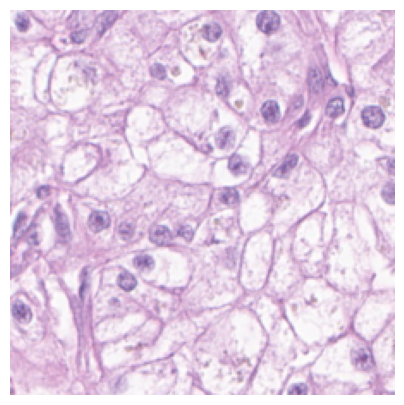

this is nearest real neighbor


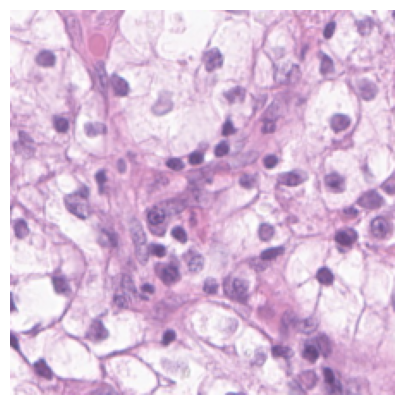

this is synthetic image at step 0


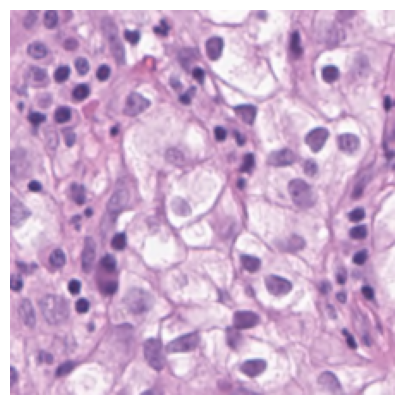

this is synthetic image at step 5


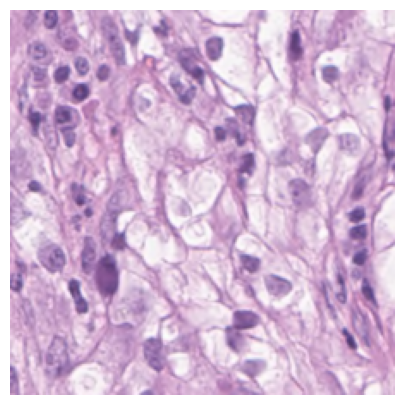

this is synthetic image at step 10


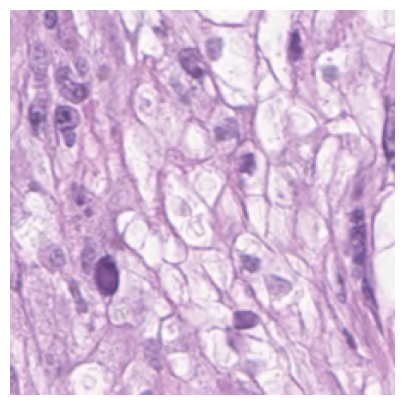

this is the closest negative sample
T1f-A3


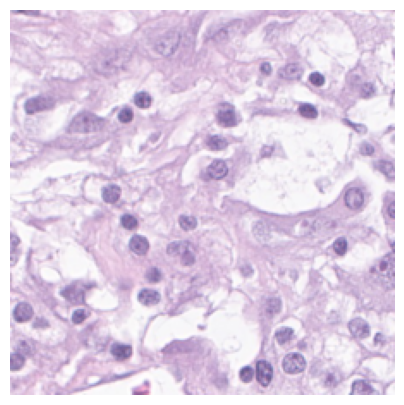

In [23]:
plt.figure(figsize=(5,5))
print('this is real original image')
plt.imshow(all_patch_data[org_real_image_idx])
plt.axis('off')
plt.show()
plt.figure(figsize=(5,5))
print('this is real target image')
plt.imshow(all_patch_data[target_real_image_idx])
plt.axis('off')
plt.show()
plt.figure(figsize=(5,5))
print('this is nearest real neighbor')
plt.imshow(all_patch_data[nearest_neighbor_idx_list['step_5'][nearest_idx, 0]])
plt.axis('off')
plt.show()
plt.figure(figsize=(5,5))
print('this is synthetic image at step 0')
plt.imshow(syn_data['traverse_image']['traverse_img_with_encoded_xT'][nearest_idx, 0].transpose(1, 2, 0))
plt.axis('off')
plt.show()
plt.figure(figsize=(5,5))
print('this is synthetic image at step 5')
plt.imshow(syn_data['traverse_image']['traverse_img_with_encoded_xT'][nearest_idx, 5].transpose(1, 2, 0))
plt.axis('off')
plt.show()
plt.figure(figsize=(5,5))
print('this is synthetic image at step 10')
plt.imshow(syn_data['traverse_image']['traverse_img_with_encoded_xT'][nearest_idx, 10].transpose(1, 2, 0))
plt.axis('off')
plt.show()
#find the idx of the consider nearest_idx in synthetic images at step_5
idx = np.where(class_syn_name == 'step_5')[0][nearest_idx]
considered_synvec = DIFFAE_syn_extracted_feature[idx]
#find the distance of all real images with negative_class to the considered synthetic vector
negative_class_idx = np.where(np.isin(all_patch_data_info, negative_class))[0]
dist = cdist(considered_synvec.reshape(1, -1), DIFFAE_extracted_feature[negative_class_idx], metric=metric)
#find 4 samples with the smallest distance
nearest_negative_idx = negative_class_idx[np.argsort(dist)[0][0]]
#plot closest negative sample
plt.figure(figsize=(5,5))
print('this is the closest negative sample')
plt.imshow(all_patch_data[nearest_negative_idx])
plt.axis('off')
print(all_patch_data_info[nearest_negative_idx])

/project/bioinformatics/Rajaram_lab/shared/Personal/Thuong/newdiffae/DIFFAE_grade/diffusion/base.py:312: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(self.conf.fp16):


this is synthetic image generated from the original image with positive condition


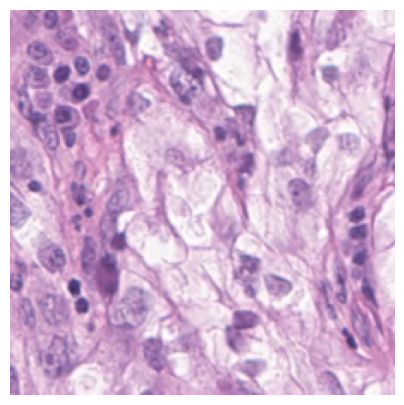

this is synthetic image generated from the original image with negative condition


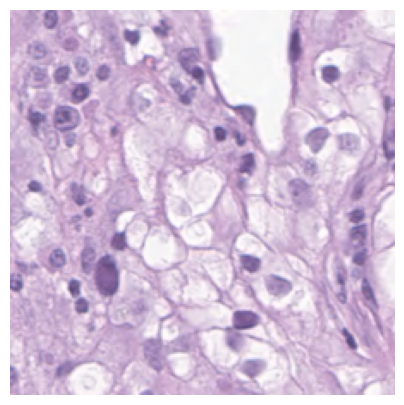

In [24]:
#generate synthetic images from the nearest negative sample and positive sample using xT from DIFFAE

org_img = all_patch_data[org_real_image_idx]
org_img_tensor = transform(Image.fromarray(org_img)).unsqueeze(0).to(device)
with torch.no_grad():
    org_cond = model.encode(org_img_tensor)
    xT =  model.encode_stochastic(org_img_tensor.to(device), org_cond, T=1000)
    
    pos_img = all_patch_data[nearest_neighbor_idx_list['step_5'][nearest_idx, 0]]
    pos_img_tensor = transform(Image.fromarray(pos_img)).unsqueeze(0).to(device)
    pos_cond = model.encode(pos_img_tensor)
    pos_syn_img = model.render(xT, pos_cond, T=250).cpu().numpy().squeeze().transpose(1, 2, 0)
    
    neg_img = all_patch_data[nearest_negative_idx]
    neg_img_tensor = transform(Image.fromarray(neg_img)).unsqueeze(0).to(device)
    neg_cond = model.encode(neg_img_tensor)
    neg_syn_img = model.render(xT, neg_cond, T=250).cpu().numpy().squeeze().transpose(1, 2, 0)

plt.figure(figsize=(5,5))
print('this is synthetic image generated from the original image with positive condition')
plt.imshow(pos_syn_img)
plt.axis('off')
plt.show()
plt.figure(figsize=(5,5))
print('this is synthetic image generated from the original image with negative condition')
plt.imshow(neg_syn_img)
plt.axis('off')
plt.show()

dict_keys(['KC01138', 'KC01888', 'KC02820'])
(2000, 512) (2000,)


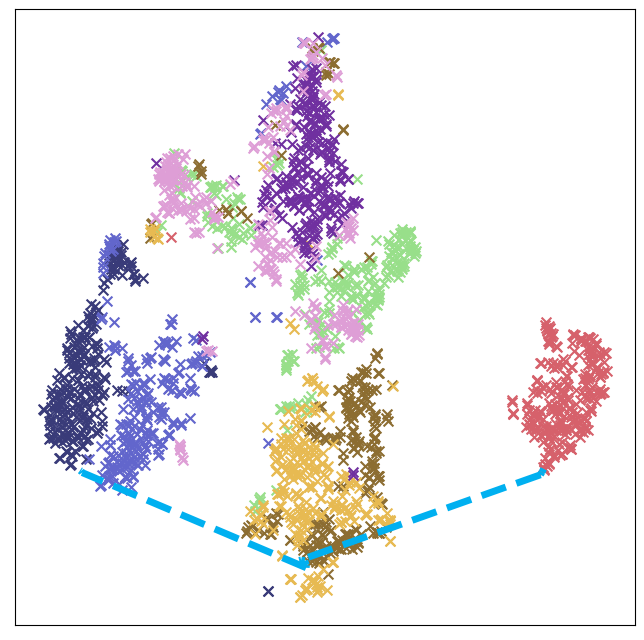

In [25]:
save_dir = file_paths['WSI1_data']['Reconstructed_latent_dir']
import pickle
with open(save_dir, 'rb') as f:
    save_file = pickle.load(f)
print(save_file.keys())
syn_DIFFAE_extracted_feature = save_file[Patient_name]['rec_feature']
class_name = save_file[Patient_name]['class_name']
print(DIFFAE_extracted_feature.shape, class_name.shape)
traversal_sample = syn_data['traverse_image']['traverse_img_with_encoded_xT'][nearest_idx].transpose(0, 2, 3, 1)
encoded_vector = []
for i in range(traversal_sample.shape[0]):
    img = traversal_sample[i]
    img = Image.fromarray(img)
    img = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        feature = model.encode(img)
    encoded_vector.append(feature.cpu().numpy().squeeze())
encoded_vector = np.array(encoded_vector)
    

# plot TSNE
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=50)
tsne_result = tsne.fit_transform(np.concatenate([syn_DIFFAE_extracted_feature, encoded_vector], axis=0))
tsne_result_encoded = tsne_result[-encoded_vector.shape[0]:]
tsne_result_reconstructed = tsne_result[:-encoded_vector.shape[0]]
color_dict = patient_data[Patient]['color_dict']
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(8,8))
for class_i in np.unique(class_name):
    idx = np.where(class_name == class_i)[0]
    plt.scatter(tsne_result_reconstructed[idx, 0], tsne_result_reconstructed[idx, 1], label=class_i, color = color_dict[class_i], s = 50, marker="x")

#plot the lines between the consecutive traverse steps in the encoded vector, with blue color and dashed lines
for i in range(encoded_vector.shape[0]-1):
    plt.plot(tsne_result_encoded[i:i+2, 0], tsne_result_encoded[i:i+2, 1], color='#00B0F0', linestyle='--', linewidth=5)
    
plt.xticks([])
plt.yticks([])
plt.show()


(10, 512)


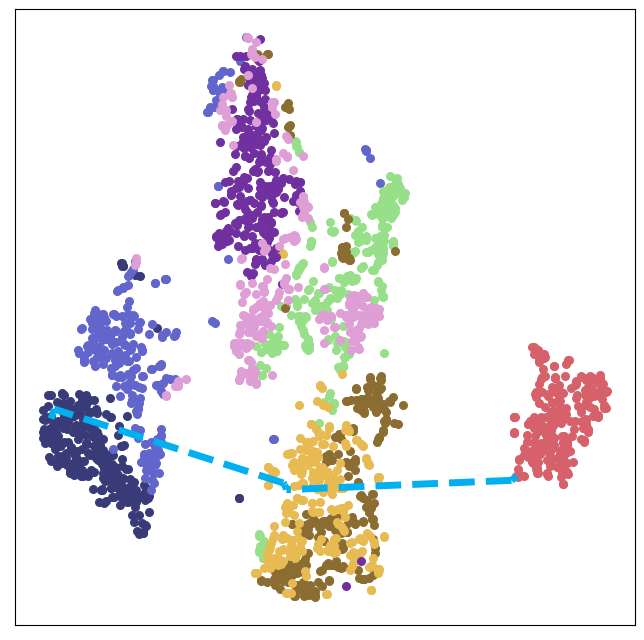

In [26]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=50)
real_encoded_list = []
real_org = all_patch_data[org_real_image_idx]
real_target = all_patch_data[target_real_image_idx]
real_org  = Image.fromarray(real_org)
real_target  = Image.fromarray(real_target)
real_org = transform(real_org).unsqueeze(0).to(device)
real_target = transform(real_target).unsqueeze(0).to(device)
with torch.no_grad():
    real_org_encoded = model.encode(real_org).cpu().numpy().squeeze()
    real_target_encoded = model.encode(real_target).cpu().numpy().squeeze()
interpolation_vector = []
for alpha in np.linspace(0, 1, num=10):
    interpolated_vector = (1 - alpha) * real_org_encoded + alpha * real_target_encoded
    interpolation_vector.append(interpolated_vector)
interpolation_vector = np.array(interpolation_vector)
print(interpolation_vector.shape)
class_name = all_patch_data_info
concatenated_feature = np.concatenate([DIFFAE_extracted_feature, interpolation_vector], axis=0)
tsne_result = tsne.fit_transform(concatenated_feature)
color_dict = patient_data[Patient]['color_dict']

import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(8,8))
for class_i in np.unique(class_name):
    idx = np.where(class_name == class_i)[0]
    plt.scatter(tsne_result[idx, 0], tsne_result[idx, 1], label=class_i, color = color_dict[class_i], s = 30)
    # plt.scatter(tsne_result[idx, 0], tsne_result[idx, 1], label=class_i, color = color_dict[class_i], s = 30, marker="x")

for i in range(len(class_name), len(class_name) + interpolation_vector.shape[0] - 1):
    plt.plot(tsne_result[i:i+2, 0], tsne_result[i:i+2, 1], color='#00B0F0', linestyle='--', linewidth=5)
    

plt.xticks([])
plt.yticks([])
plt.show()